# Comparable sales

An appraiser prices a home from recent sales of similar homes nearby. This notebook adds that as a feature: for each home, the prices of the **10 nearest sales that closed in the 12 months before its listing month**.

- `LogCompPricePerSqft`: log of their median price per square foot.
- `LogCompImpliedPrice`: log of that times the home's living area, i.e. what the home would cost at its neighbours' rate.
- `CompDistanceKm`: their mean distance, i.e. how local the comparison is.

The model predicts before the home is listed, so only sales that closed before the listing month can be used. The home's own sale never counts as a comparable, because it closes after it lists. Homes with no listing date are assumed to list 2 months before close (the median gap).

Tested against the current best: first with linear regression as a quick screen, then with the random forest, which decides. Setup as before: X = 18 months, compared on the 6 validation months 2025-10 to 2026-03. The test month, 2026-04, is held out and never scored.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from idx_exchange_data_science import dataset_a as da
from idx_exchange_data_science import features as ft
from idx_exchange_data_science.modeling import (
    backtest, build_model, feature_importances, fit_window, gain_summary, linear_baseline, median_ape_by, random_forest,
)
from idx_exchange_data_science.splits import validation_months

pd.set_option("display.float_format", "{:,.4f}".format)
COLORS = ["#2a78d6", "#eb6834"]

X = 18
EVAL_MONTHS = validation_months("2026-04", n_months=6)  # 2025-10 to 2026-03; 2026-04 is the held-out test month
METRICS = ["r2", "mae", "mape", "median_ape", "within_10pct"]
RESULTS_DIR = Path("../results")
SIZE_BANDS = [0, 1000, 1500, 2000, 2500, 3000, 4000, 5000, np.inf]

df = ft.build_table()  # Dataset A + school districts + listing date + comparable sales
df.shape

(309019, 28)

## 1. The new feature

In [2]:
year = df[da.DATE_COL].dt.year
coverage = df.groupby(year)["LogCompPricePerSqft"].apply(lambda s: s.notna().mean()).to_frame("share with comparables")
coverage["median distance (km)"] = df.groupby(year)["CompDistanceKm"].median()
coverage

,share with comparables,median distance (km)
CloseDate,,
2024,0.7720,0.6527
2025,0.9978,0.3365
2026,0.9947,0.3345


In [3]:
recent = df[df[da.DATE_COL] >= "2024-10-01"]
pct_error = np.abs(np.exp(recent["LogCompImpliedPrice"]) / recent[da.TARGET] - 1)
spearman = df[[*ft.COMP_COLS, "LivingArea"]].corrwith(df[da.TARGET], method="spearman").to_frame("spearman_r")
print(f"Comparable-implied price on its own (sales since 2024-10): median error {pct_error.median():.1%}, "
      f"within 10% for {(pct_error < 0.1).mean():.0%} of homes")
spearman

Comparable-implied price on its own (sales since 2024-10): median error 13.0%, within 10% for 40% of homes


,spearman_r
LogCompPricePerSqft,0.7982
LogCompImpliedPrice,0.9381
CompDistanceKm,0.0054
LivingArea,0.5072


**Observations**
- **Coverage is near complete from 2025 on** (99.5%+). In 2024 it is 77%, because sales listed early in 2024 have little or no earlier data to look back on. Those rows get the training-median fill. The training windows for the validation months start in 2024-04 or later, so this mostly affects their oldest months.
- **Comparables are local:** the 10 nearest earlier sales are a median of about 0.3 km away.
- **The comparable-implied price is the strongest single predictor so far** (Spearman 0.94, against 0.51 for living area). On its own it is within 10% of the actual price for 40% of homes, with a median error of 13%.

## 2. Models
Each model is run on the current best feature set (Dataset A + school districts) with and without the comparable-sales columns. Besides R², MAE and MAPE (the **mean** absolute percentage error), the tables report the **median** absolute percentage error and the share of homes predicted within 10%, the usual accuracy measures for automated valuations. All are means over the 6 validation months.

In [4]:
FEATURE_SETS = {"Districts (current best)": [], "+ comparable sales": ft.COMP_COLS}


def forest(numeric, categorical):
    return build_model(random_forest(), da.make_preprocessor(numeric, categorical))


def compare(make_model):
    """Backtest `make_model(numeric, categorical)` on each feature set; print the month-by-month R² gain."""
    models = {name: make_model(ft.DISTRICT_NUMERIC_COLS + extra, ft.DISTRICT_COLS) for name, extra in FEATURE_SETS.items()}
    scores, predictions = backtest(models, df, EVAL_MONTHS, X)
    print(gain_summary(scores, reference="Districts (current best)").to_string())
    return scores.groupby("model")[METRICS].mean().loc[list(FEATURE_SETS)], scores, predictions, models

## 3. Quick screen: linear regression
Linear regression can't group nearby homes the way a forest can with the coordinates, so it should gain more from this feature than the forest will. If it gains nothing, the feature is not worth pursuing.

In [5]:
linear_summary, linear_validation, _, _ = compare(linear_baseline)
linear_summary

                    mean gain  std gain  months improved (of 6)
model                                                          
+ comparable sales     0.0523    0.0121                       6


,r2,mae,mape,median_ape,within_10pct
model,,,,,
Districts (current best),0.8018,"205,336.1209",0.1592,0.1179,0.4352
+ comparable sales,0.8542,"175,496.1569",0.1381,0.1011,0.4952


**Observations**
- **The screen passes clearly.** Validation R² rises by 0.052 (0.802 → 0.854) and improves in all 6 months. MAE falls from \$205K to \$175K and the median % error from 11.8% to 10.1%.
- As expected, linear regression gains a lot, because it had no way of using neighbourhood prices beyond the ZIP, city and district averages. The forest decides.

## 4. Random forest

In [6]:
forest_summary, forest_validation, forest_predictions, forest_models = compare(forest)
forest_summary

                    mean gain  std gain  months improved (of 6)
model                                                          
+ comparable sales     0.0065    0.0030                       6


,r2,mae,mape,median_ape,within_10pct
model,,,,,
Districts (current best),0.8923,"151,207.2719",0.1196,0.0774,0.5969
+ comparable sales,0.8989,"149,755.4190",0.1196,0.0786,0.5929


In [7]:
evaluated = df.loc[forest_predictions.index]
size = pd.cut(evaluated["LivingArea"], SIZE_BANDS, right=False)
error_by_size = median_ape_by(forest_predictions, evaluated[da.TARGET], size)
error_by_size.insert(0, "sales", evaluated.groupby(size, observed=True).size())
error_by_size["change"] = error_by_size["+ comparable sales"] - error_by_size["Districts (current best)"]
error_by_size

,sales,Districts (current best),+ comparable sales,change
LivingArea,,,,
"[0.0, 1000.0)",3268,8.7654,9.0682,0.3027
"[1000.0, 1500.0)",15550,7.1239,7.2002,0.0763
"[1500.0, 2000.0)",16160,6.9964,7.1555,0.1591
"[2000.0, 2500.0)",10655,7.3804,7.6051,0.2247
"[2500.0, 3000.0)",6231,8.4018,8.3128,-0.0891
"[3000.0, 4000.0)",5217,9.9216,9.9833,0.0617
"[4000.0, 5000.0)",1509,12.2522,12.4306,0.1784
"[5000.0, inf)",800,13.6318,13.1938,-0.4380


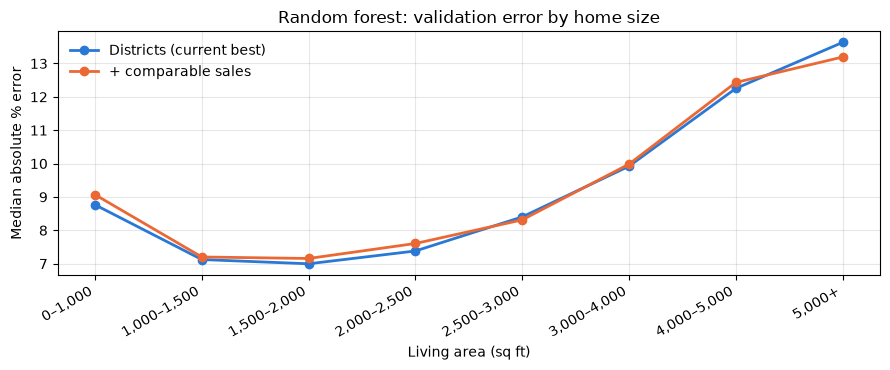

In [8]:
labels = [f"{int(b.left):,}+" if np.isinf(b.right) else f"{int(b.left):,}–{int(b.right):,}" for b in error_by_size.index]
fig, ax = plt.subplots(figsize=(9, 3.8))
for color, name in zip(COLORS, FEATURE_SETS):
    ax.plot(range(len(error_by_size)), error_by_size[name], marker="o", markersize=6, linewidth=2, color=color, label=name)
ax.set(xticks=range(len(error_by_size)), xlabel="Living area (sq ft)", ylabel="Median absolute % error",
       title="Random forest: validation error by home size")
ax.set_xticklabels(labels, rotation=30, ha="right")
ax.grid(alpha=0.3)
ax.legend(frameon=False)
plt.tight_layout()

In [9]:
# fit on the 18 months before the last validation month
importance = feature_importances(fit_window(forest_models["+ comparable sales"], df, EVAL_MONTHS[-1], X))
importance.sort_values(ascending=False).head(10).to_frame("importance")

,importance
LogCompImpliedPrice,0.4022
PostalCode,0.1749
City,0.0884
LivingArea,0.0792
LogCompPricePerSqft,0.0683
ElementaryDistrict,0.0401
BathroomsTotalInteger,0.0392
HighDistrict,0.0277
LotSizeSquareFeet,0.0153
PropertyAge,0.0097


**Observations**
- **The forest improves in R² and dollars.** Validation R² rises in all 6 months (+0.0065 on average, 0.892 → 0.899), and MAE falls in 5 of 6 (by \$1.5K on average, to \$149.8K).
- **Percentage error doesn't improve.** The mean % error is flat (12.0%, better in only 3 of 6 months). The median % error is slightly worse in all 6 months (7.7% → 7.9%), and 59.3% of homes are within 10% vs 59.7%.
- **The gain is concentrated in expensive homes.** Above 5,000 sq ft median error drops from 13.6% to 13.2%, while most bands below 2,500 sq ft get slightly worse (by 0.1–0.3 points). R² and MAE are in dollars, so they weight expensive homes heavily, and the forest is fit on dollars too, so it spends its splits where the dollar errors are.
- **The forest relies on the feature heavily:** the comparable-implied price takes 40% of importance, ahead of the ZIP encoding (17%).

## Summary
Means over the 6 validation months (2025-10 to 2026-03):

| Random Forest + school districts | R² | MAE | Mean % error | Median % error | Within 10% |
|---|---|---|---|---|---|
| Without comparable sales | 0.892 | \$151.2K | 12.0% | 7.7% | 59.7% |
| With comparable sales | **0.899** | **\$149.8K** | 12.0% | 7.9% | 59.3% |

- **Comparable sales give the strongest model so far in R² and dollar error**, consistently across validation months.
- **For a typical home's percentage error they don't help.** Whether to adopt them depends on which metric matters most. If percentage error is the target, the next thing to try is the same model with a log target. That would make the forest minimize relative error, so it may turn the comparables into a gain for typical homes too. In `04_model_comparison.ipynb` the log target already lowered the mean % error.

In [10]:
results = pd.concat([linear_summary.assign(estimator="Linear Regression"),
                     forest_summary.assign(estimator="Random Forest")]).reset_index()
results.to_csv(RESULTS_DIR / "comparable_sales_comparison.csv", index=False)
pd.concat([linear_validation.assign(estimator="Linear Regression"),
           forest_validation.assign(estimator="Random Forest")]).to_csv(
    RESULTS_DIR / "comparable_sales_backtest.csv", index=False)